# Tutorial 5: self-supervised learning: the contrastive loss, EMA teachers, CLIP and DINO
**Deep Learning 89-6877, Fall 2026.** TA: Tal Fiskus.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/idansc/dl-course-2026/blob/main/tutorials/T05_self_supervised.ipynb)
Recap slides: [T05_self_supervised_recap.pdf](https://github.com/idansc/dl-course-2026/blob/main/tutorials/recap/T05_self_supervised_recap.pdf)

Plan for today (≈ 60 min):
1. Lecture recap: linear probe, InfoNCE, CLIP/SigLIP, MoCo, DINO, JEPA masks (10 min)
2. The contrastive loss, built step by step: from a similarity matrix to InfoNCE, its gradient, why it needs many negatives, a short SimCLR run (15 min)
3. EMA and the queue: MoCo, and what the momentum is for (12 min)
4. CLIP and SigLIP: InfoNCE across modalities, zero-shot classification, the sigmoid loss (10 min)
5. DINO: centering and sharpening (10 min)
6. Effective rank: detecting collapse without labels (5 min)
7. If time: what to hide, random patches or blocks (V-JEPA)

Runs in about 4 minutes on a laptop CPU, 1 minute on a GPU (a 5000-image CIFAR-10 subset; CLIP ViT-B/32, 600 MB, downloads on first run). Cells marked ✏️ are for you to try.
On a Colab GPU, scale up with `N_PRE`, the step counts and the batch sizes; the comments next to them say where.

In [1]:
import copy, math, random, time
from collections import deque
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
from transformers import CLIPModel, CLIPProcessor
torch.manual_seed(0); random.seed(0); np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("device:", device)
T0 = time.time()

device: mps


## 1. Lecture recap

**Self-supervised learning.** Train an encoder $f$ on a task whose labels come from the data itself (a rotation, the colors, a second view of the same image, the image's caption, a hidden part of the image); then freeze $f$ and measure it with a **linear probe**, $\hat y = \mathrm{softmax}(W f(x) + b)$, where only $W, b$ are trained.

**InfoNCE.** An anchor $q$, one positive $k^+$ (another view of the same image, or its caption) and negatives $k_1^-, k_2^-, \dots$ (the rest of the batch). With cosine similarity $s$ and temperature $\tau$,
$$\mathcal L = -\log\frac{e^{s(q,k^+)/\tau}}{e^{s(q,k^+)/\tau}+\sum_j e^{s(q,k_j^-)/\tau}},$$
a classification whose correct class is the positive. With $N$ candidates per anchor, $I(q;k^+) \ge \log N - \mathcal L$: the loss bounds the mutual information between the two views from below, and the bound never exceeds $\log N$.

**SimCLR**: $N$ images, two augmentations each; each view's positive is the other view of its image and its negatives are the other $2N-2$ views. **CLIP**: $N$ image–text pairs; the same loss on the $N\times N$ image–text similarity matrix, along the rows (image → text) and along the columns (text → image), averaged. Zero-shot classification: embed "a photo of a {class}." for every class and pick the closest. **SigLIP**: an independent sigmoid on every image–text pair, $\mathcal L = -\frac1N\sum_{i,j}\log\sigma\big(z_{ij}(t\,s_{ij}+b)\big)$ with $z_{ii}=1$, $z_{i\ne j}=-1$, so no normalization over the batch.

**Large batches.** Negatives come from the batch, so SimCLR and CLIP need very large batches (CLIP: 32,768). **MoCo** takes its negatives from a **queue** of keys from the last $K/B$ batches, computed by a **momentum encoder**: an exponential moving average (EMA) of the query encoder, $\theta_k \leftarrow m\,\theta_k + (1-m)\,\theta_q$ with $m = 0.999$.

**DINO (self-distillation).** The student matches the teacher across two views, $\mathcal L = -\sum_k p_t^{(k)}\log p_s^{(k)}$ with $p_s = \mathrm{softmax}(z_s/\tau_s)$. The teacher is an EMA of the student and gets no gradient. A constant output matches perfectly, so two operations on the teacher's output prevent collapse: **centering**, $p_t = \mathrm{softmax}\big((z_t - c)/\tau_t\big)$ with $c$ a running mean of $z_t$ (no output dimension can win for every image), and **sharpening**, a small $\tau_t$ (the output cannot be uniform).

**Masked prediction (MAE, I-JEPA, V-JEPA).** Hide part of the input and predict it. MAE predicts the pixels of 75% random patches; JEPA predicts the *features* of the hidden part, given by an EMA target encoder. V-JEPA hides big blocks, the same in every frame: 8 blocks of 15% of the frame, or 2 of 70%.

### From earlier tutorials
A small CNN: the encoder for every method in this notebook (64-d output).

In [2]:
class SmallCNN(nn.Module):
    # 32x32 RGB in [0,1] -> 4w-d feature (64-d by default)
    def __init__(self, w=16):
        super().__init__()
        def blk(i, o, s): return [nn.Conv2d(i, o, 3, s, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU()]
        self.net = nn.Sequential(*blk(3, w, 1), *blk(w, 2 * w, 2), *blk(2 * w, 4 * w, 2), *blk(4 * w, 4 * w, 2),
                                 nn.AdaptiveAvgPool2d(1), nn.Flatten())
        self.register_buffer("mean", torch.tensor([0.491, 0.482, 0.447]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.247, 0.243, 0.262]).view(1, 3, 1, 1))
        self.out_dim = 4 * w
    def forward(self, x):
        return self.net((x - self.mean) / self.std)

**Data.** `N_PRE = 5000` unlabeled CIFAR-10 training images for pretraining; the linear probes use the labels of the first 2000 of them and 1000 test images. (Colab GPU: `N_PRE = 50000` and more steps below.)

In [3]:
cifar_tr = torchvision.datasets.CIFAR10("./data", train=True, download=True)
cifar_te = torchvision.datasets.CIFAR10("./data", train=False, download=True)
CLASSES = cifar_tr.classes
def to_tensor(ds, idx):
    return torch.tensor(ds.data[idx]).permute(0, 3, 1, 2).float() / 255, torch.tensor(ds.targets)[idx]

N_PRE, N_PROBE, N_TEST = 5000, 2000, 1000          # Colab GPU: N_PRE = 50000
g = torch.Generator().manual_seed(0)
X_pre, y_pre = to_tensor(cifar_tr, torch.randperm(50000, generator=g)[:N_PRE])
X_te, y_te = to_tensor(cifar_te, torch.randperm(10000, generator=g)[:N_TEST])
X_probe, y_probe = X_pre[:N_PROBE], y_pre[:N_PROBE]
X_pre_d = X_pre.to(device)
print(X_pre.shape, X_te.shape)

torch.Size([5000, 3, 32, 32]) torch.Size([1000, 3, 32, 32])


## 2. The contrastive loss, built step by step

### 2.1 Two views of each image
SimCLR's positive pair is two random augmentations of one image: a **random resized crop** (20–100% of the area, random horizontal flip) and **color distortion** (brightness, contrast, saturation, sometimes grayscale). Whatever the augmentations change, the features learn to ignore. The code is given: batched tensor ops, so every image in the batch gets its own random parameters (a crop is one affine map, applied with `F.affine_grid` + `F.grid_sample`).

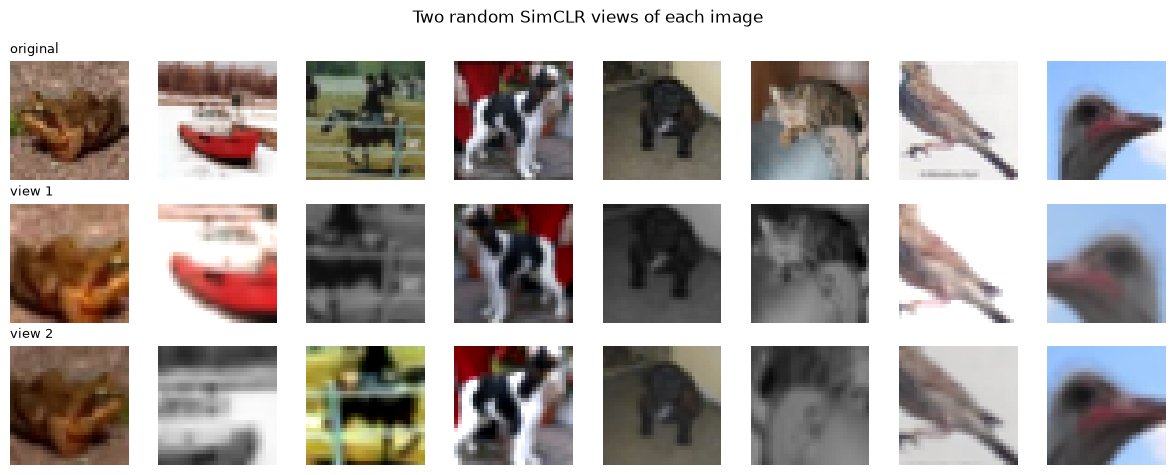

In [4]:
def crop_flip(x, side, tx, ty, flip):
    # x: (B,3,H,W); a crop of relative side `side` centred at (tx, ty) in [-1,1] coordinates, flip = ±1
    theta = torch.zeros(x.shape[0], 2, 3, device=x.device)
    theta[:, 0, 0], theta[:, 0, 2], theta[:, 1, 1], theta[:, 1, 2] = side * flip, tx, side, ty
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    return F.grid_sample(x, grid, mode="bilinear", padding_mode="reflection", align_corners=False)

def augment(x, min_area=0.2):
    B, dev = x.shape[0], x.device
    side = torch.empty(B, device=dev).uniform_(min_area, 1.0).sqrt()       # crop area fraction in [0.2, 1]
    tx, ty = [(torch.rand(B, device=dev) * 2 - 1) * (1 - side) for _ in range(2)]
    flip = torch.where(torch.rand(B, device=dev) < 0.5, -1.0, 1.0)
    x = crop_flip(x, side, tx, ty, flip)
    # color jitter with prob 0.8: brightness, contrast, saturation (strength 0.4)
    jit = (torch.rand(B, 1, 1, 1, device=dev) < 0.8).float()
    def r(): return 1 + jit * (torch.rand(B, 1, 1, 1, device=dev) * 0.8 - 0.4)
    gray = (0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3])
    x = x * r()
    x = (x - x.mean((1, 2, 3), keepdim=True)) * r() + x.mean((1, 2, 3), keepdim=True)
    x = gray + (x - gray) * r()
    # grayscale with prob 0.2
    to_gray = (torch.rand(B, 1, 1, 1, device=dev) < 0.2).float()
    gray = (0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3])
    x = to_gray * gray.expand_as(x) + (1 - to_gray) * x
    return x.clamp(0, 1)

torch.manual_seed(0)
xb = X_pre[:8]
fig, axes = plt.subplots(3, 8, figsize=(12, 4.8))
for i in range(8):
    for row, img in enumerate([xb[i], augment(xb[i:i + 1])[0], augment(xb[i:i + 1])[0]]):
        axes[row, i].imshow(img.permute(1, 2, 0).numpy()); axes[row, i].axis("off")
for row, t in enumerate(["original", "view 1", "view 2"]):
    axes[row, 0].set_title(t, loc="left", fontsize=9)
fig.suptitle("Two random SimCLR views of each image"); plt.tight_layout(); plt.show()

### 2.2 From a similarity matrix to InfoNCE
Stack the two views' embeddings as $z = [z^{(1)}; z^{(2)}] \in \mathbb{R}^{2N\times d}$, L2-normalize the rows, and form the $2N\times 2N$ matrix $S = zz^\top/\tau$ of cosine similarities over the temperature. Then:
1. a view is not its own negative: set the diagonal of $S$ to $-\infty$;
2. row $i$ is now a $(2N-1)$-way classification, and its correct class is the other view of the same image: column $i+N$ for $i<N$, column $i-N$ otherwise;
3. so InfoNCE (SimCLR calls it NT-Xent) is `F.cross_entropy` on the rows of $S$.

In [5]:
def nt_xent(z1, z2, tau=0.5):
    N = z1.shape[0]
    z = F.normalize(torch.cat([z1, z2]), dim=1)
    sim = (z @ z.T) / tau
    sim = sim.masked_fill(torch.eye(2 * N, dtype=torch.bool, device=z.device), float("-inf"))
    targets = torch.cat([torch.arange(N, 2 * N), torch.arange(0, N)]).to(z.device)
    return F.cross_entropy(sim, targets)

def nt_xent_reference(z1, z2, tau=0.5):
    # the formula, one anchor at a time
    z = torch.cat([z1, z2]); N2 = z.shape[0]; losses = []
    for i in range(N2):
        p = (i + N2 // 2) % N2
        sims = torch.stack([F.cosine_similarity(z[i], z[k], dim=0) / tau for k in range(N2)])
        denom = sum(torch.exp(sims[k]) for k in range(N2) if k != i)
        losses.append(-torch.log(torch.exp(sims[p]) / denom))
    return torch.stack(losses).mean()

In [6]:
torch.manual_seed(0)
z1, z2 = torch.randn(6, 16), torch.randn(6, 16)
print(f"random pairs:    mine {nt_xent(z1, z2):.6f}   reference {nt_xent_reference(z1, z2):.6f}")
z2b = z1 + 0.05 * torch.randn(6, 16)
print(f"matching pairs:  mine {nt_xent(z1, z2b):.6f}   reference {nt_xent_reference(z1, z2b):.6f}")
print(f"log(2N−1) = {math.log(11):.4f} (all logits equal)")

random pairs:    mine 2.694572   reference 2.694572
matching pairs:  mine 0.832317   reference 0.832317
log(2N−1) = 2.3979 (all logits equal)


Mine and the reference agree to 6 decimals. Random pairs give 2.69, close to $\log(2N-1) = 2.40$ (the loss when all $2N-1$ logits are equal); matching pairs give 0.83.

### 2.3 What the gradient does: easy and hard negatives
**Past exam question (Moed B, 2026).** In contrastive learning with the InfoNCE loss, the quality and difficulty of the negative samples strongly affect the quality of the learned representations. **Hard negatives** are negatives whose representations the current model already places relatively close to the anchor $q$ (i.e. $\mathrm{sim}(q,k_i^-)$ is relatively high), although they are not truly positive. A researcher trains a contrastive model and finds that after a few epochs most of the random negatives in the batch are "easy", i.e. $\mathrm{sim}(q,k_i^-)\ll\mathrm{sim}(q,k^+)$, so the loss becomes very small and contributes a negligible gradient.
**Explain theoretically why easy negatives give a small gradient (refer to the form of the softmax in InfoNCE), and propose *one* practical method for hard negative mining during training.** Explain why your method leads to better representations, and name a possible risk of extreme use of hard negatives.
**Answer.** With $s^+=\mathrm{sim}(q,k^+)$, $s_i^-=\mathrm{sim}(q,k_i^-)$:
$$\mathcal L=-\log\frac{e^{s^+/\tau}}{e^{s^+/\tau}+\sum_j e^{s_j^-/\tau}},\qquad \frac{\partial\mathcal L}{\partial s_i^-}=\frac{p_i^-}{\tau},\quad p_i^-=\frac{e^{s_i^-/\tau}}{e^{s^+/\tau}+\sum_j e^{s_j^-/\tau}},\qquad \frac{\partial\mathcal L}{\partial s^+}=-\frac{1-p^+}{\tau}.$$
Each negative is pushed away in proportion to its softmax probability. If $s_i^-\ll s^+$, the denominator is dominated by the positive, $p_i^-\approx e^{-(s^+-s_i^-)/\tau}\to0$, and $p^+\to1$: both the loss and every gradient vanish exponentially in the margin.

*Method:* keep a large pool of candidate keys (the batch, or a memory queue as in MoCo, section 3), and for each anchor use the top-$k$ most similar keys as negatives (alternatives: synthesize harder negatives by mixing the hardest ones, MoCHi; or reweight negatives by similarity, Robinson et al. 2021). *Why it helps:* these negatives carry non-negligible $p_i^-$, hence gradient, and force the encoder to separate similar but different images: finer-grained features. *Risk:* the most similar "negatives" are often **false negatives** (another image of the same class or object); pushing them away removes exactly the semantic similarity we want, and with label-free data it cannot be detected directly. Extreme mining also makes training unstable.

(Minor: the official solution describes MoCHi as mixing the input representations *and the positive*; MoCHi mixes the hardest negatives with each other and with the query, not with the positive.)

**In code.** One anchor with a positive at similarity 0.9 and $\tau = 0.1$; compare autograd with the formula $\partial\mathcal L/\partial s_i^- = p_i^-/\tau$.

In [7]:
tau_q = 0.1
s_pos = torch.tensor([0.9])
cases = {"easy: 10 negatives at s=0.10        ": torch.full((10,), 0.1),
         "hard: 1 negative at s=0.85, 9 at 0.10": torch.tensor([0.85] + [0.1] * 9)}
for name, s_neg in cases.items():
    s = torch.cat([s_pos, s_neg]).requires_grad_(True)
    loss_q = -F.log_softmax(s / tau_q, 0)[0]
    loss_q.backward()
    grad_neg = F.softmax(s.detach() / tau_q, 0)[1:] / tau_q
    print(f"{name}: loss {loss_q.item():.4f}  dL/ds_neg max: autograd {s.grad[1:].max():.2e}, analytic {grad_neg.max():.2e} "
          f"(diff {(s.grad[1:] - grad_neg).abs().max():.0e})   dL/ds_pos {s.grad[0]:.2e}")

easy: 10 negatives at s=0.10        : loss 0.0033  dL/ds_neg max: autograd 3.34e-03, analytic 3.34e-03 (diff 1e-09)   dL/ds_pos -3.34e-02
hard: 1 negative at s=0.85, 9 at 0.10: loss 0.4760  dL/ds_neg max: autograd 3.77e+00, analytic 3.77e+00 (diff 9e-10)   dL/ds_pos -3.79e+00


With $\tau=0.1$, ten easy negatives give loss 0.003 and a gradient of $3.3\times10^{-3}$ on each; one hard negative at 0.85 raises the loss to 0.48 and receives a gradient of 3.8, about 1100× more, while the nine easy ones still get almost nothing. Autograd and the formula agree to $10^{-9}$.

### 2.4 Why InfoNCE needs many negatives
$\mathcal L \ge 0$, so the bound $\log N - \mathcal L$ is at most $\log N$: with $N$ candidates per anchor, the loss can certify at most $\log N$ nats of shared information, however good the encoder is. A toy with a known answer: $x, y \in \mathbb R^{20}$ Gaussian with per-dimension correlation $\rho$, so $I(x;y) = -\tfrac{20}{2}\log(1-\rho^2)$, set to 6 nats. Instead of training an encoder we use the best possible critic, $s(x,y) = \log p(y\,|\,x) - \log p(y)$ (here $\tau = 1$), and compute the InfoNCE estimate $\log N - \mathcal L$ for growing $N$.

N =     4   log N =  1.39   InfoNCE estimate log N − L = 1.39   (true I = 6.0)
N =    16   log N =  2.77   InfoNCE estimate log N − L = 2.16   (true I = 6.0)
N =    64   log N =  4.16   InfoNCE estimate log N − L = 3.86   (true I = 6.0)
N =   256   log N =  5.55   InfoNCE estimate log N − L = 4.67   (true I = 6.0)
N =  1024   log N =  6.93   InfoNCE estimate log N − L = 5.26   (true I = 6.0)
N =  4096   log N =  8.32   InfoNCE estimate log N − L = 5.62   (true I = 6.0)


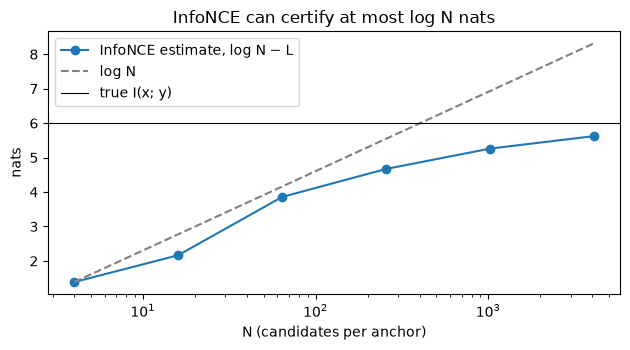

In [8]:
d, I_TRUE = 20, 6.0
rho = math.sqrt(1 - math.exp(-2 * I_TRUE / d))         # per-dimension correlation giving I(x; y) = 6 nats

def critic(x, y):
    # the best critic for InfoNCE, s(x, y) = log p(y|x) − log p(y), for every pair (x_i, y_j) -> (N, N)
    s2 = 1 - rho ** 2
    return -torch.cdist(rho * x, y) ** 2 / (2 * s2) + (y ** 2).sum(1)[None, :] / 2 - d / 2 * math.log(s2)

torch.manual_seed(0)
Ns, est = [4, 16, 64, 256, 1024, 4096], []
for N in Ns:
    x = torch.randn(N, d)
    y = rho * x + math.sqrt(1 - rho ** 2) * torch.randn(N, d)
    S = critic(x, y)                                     # row i: x_i against every y_j; the positive is y_i
    est.append(math.log(N) - F.cross_entropy(S, torch.arange(N)).item())
    print(f"N = {N:5d}   log N = {math.log(N):5.2f}   InfoNCE estimate log N − L = {est[-1]:.2f}   (true I = {I_TRUE})")
fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.plot(Ns, est, "o-", label="InfoNCE estimate, log N − L")
ax.plot(Ns, np.log(Ns), "--", c="0.5", label="log N")
ax.axhline(I_TRUE, c="k", lw=0.8, label="true I(x; y)")
ax.set(xscale="log", xlabel="N (candidates per anchor)", ylabel="nats", title="InfoNCE can certify at most log N nats")
ax.legend(); plt.tight_layout(); plt.show()

The estimate never exceeds $\log N$: $N = 16$ certifies 2.16 nats, $N = 4096$ certifies 5.62 of the true 6. It gets close to $I$ only when the number of candidates is well above $e^{I} \approx 400$. This is why SimCLR trains with batches of 4096 ($\log N = 8.3$) and CLIP with 32,768 (10.4), and why MoCo keeps a queue of 65,536 keys (11.1).

### 2.5 A short SimCLR run and a linear probe
Encoder $f$ = `SmallCNN` (64-d), projection head $g$ = MLP 64→128→64, Adam, $\tau=0.5$, batch 256, 12 epochs on 5000 images (228 steps). The paper uses LARS, batch 4096 and 800 epochs on ImageNet; this is a toy version of the same objective. The probe: freeze $f$, take the 64-d features **before** the projection head, standardize them, and fit multinomial logistic regression with an L2 penalty (L-BFGS, given).

In [9]:
torch.manual_seed(0)
enc = SmallCNN().to(device)
head = nn.Sequential(nn.Linear(enc.out_dim, 128), nn.ReLU(), nn.Linear(128, 64)).to(device)
opt = torch.optim.Adam(list(enc.parameters()) + list(head.parameters()), lr=2e-3, weight_decay=1e-5)
EPOCHS_SIMCLR, BS = 12, 256                         # Colab GPU: SmallCNN(32), 100+ epochs on N_PRE = 50000
simclr_losses, t0 = [], time.time()
for ep in range(EPOCHS_SIMCLR):
    perm = torch.randperm(N_PRE, device=device)
    for k in range(0, N_PRE - BS + 1, BS):
        xb = X_pre_d[perm[k:k + BS]]
        loss = nt_xent(head(enc(augment(xb))), head(enc(augment(xb))))   # two views -> encoder -> head -> InfoNCE
        opt.zero_grad(); loss.backward(); opt.step()
        simclr_losses.append(loss.item())
    if ep % 4 == 0 or ep == EPOCHS_SIMCLR - 1:
        print(f"epoch {ep:2d}  InfoNCE {np.mean(simclr_losses[-(N_PRE // BS):]):.3f}   ({time.time() - t0:.0f}s)")
print(f"chance level log(2·{BS}−1) = {math.log(2 * BS - 1):.3f}")

epoch  0  InfoNCE 5.638   (1s)


epoch  4  InfoNCE 5.123   (2s)


epoch  8  InfoNCE 5.038   (4s)


epoch 11  InfoNCE 4.999   (6s)
chance level log(2·256−1) = 6.236


In [10]:
@torch.no_grad()
def extract(f, X, bs=500):
    f.eval()
    out = torch.cat([f(X[k:k + bs].to(device)).float().cpu() for k in range(0, len(X), bs)])
    f.train()
    return out

def linear_probe(Htr, ytr, Hte, yte, wd=1e-3, iters=200):
    # standardized features, mean cross-entropy + (wd/2)·||W||², minimized to convergence with L-BFGS
    mu, sd = Htr.mean(0), Htr.std(0) + 1e-6
    Htr, Hte = (Htr - mu) / sd, (Hte - mu) / sd
    W = torch.zeros(Htr.shape[1], int(ytr.max()) + 1, requires_grad=True)
    b = torch.zeros(W.shape[1], requires_grad=True)
    opt = torch.optim.LBFGS([W, b], lr=1, max_iter=iters, history_size=20, line_search_fn="strong_wolfe")
    def closure():
        opt.zero_grad()
        loss = F.cross_entropy(Htr @ W + b, ytr) + wd / 2 * (W ** 2).sum()
        loss.backward()
        return loss
    opt.step(closure)
    return ((Hte @ W + b).argmax(1) == yte).float().mean().item()

def probe(f):
    # frozen encoder -> linear-probe test accuracy (2000 labeled training images, 1000 test images)
    return linear_probe(extract(f, X_probe), y_probe, extract(f, X_te), y_te)

acc = {"SimCLR": probe(enc)}
torch.manual_seed(0)
rand_enc = SmallCNN().to(device)                     # same architecture, never trained
acc["random init"] = probe(rand_enc)
acc_pixels = linear_probe(X_probe.flatten(1), y_probe, X_te.flatten(1), y_te)
print(f"linear probe test accuracy: SimCLR {acc['SimCLR']:.3f}, random-init SmallCNN {acc['random init']:.3f}, "
      f"raw pixels {acc_pixels:.3f}, chance 0.100")

linear probe test accuracy: SimCLR 0.439, random-init SmallCNN 0.296, raw pixels 0.264, chance 0.100


The loss fell from 5.64 to 5.00 ($\log(2N-1) = 6.24$), far from converged. SimCLR features reach **0.439** under the linear probe; the same CNN at random init gives 0.296 and raw pixels 0.264. So 228 steps on 5000 unlabeled images add ≈ 14 points over the architecture alone. The augmentations are drawn differently on CPU, MPS and CUDA, so your numbers will move by a few points (these outputs are from an Apple-silicon GPU; a CPU run gives SimCLR 0.467, random init 0.294).

✏️ Set `min_area=1.0` (no cropping) in `augment` and rerun 2.5. The SimCLR paper (Fig. 5) found crop + color the pair of augmentations that matters most; what happens to the probe accuracy without crops?

## 3. EMA and the queue: MoCo
In SimCLR the negatives are the other images in the batch, so more negatives means a bigger batch (section 2.4). MoCo separates the two: the negatives are the **keys** of the last $K/B$ batches, kept in a **queue**, and the keys are computed by a separate **key encoder** that is a slow **exponential moving average** of the query encoder.

### 3.1 The exponential moving average
$\theta_k \leftarrow m\,\theta_k + (1-m)\,\theta_q$ after every step. Unrolled over $t$ steps,
$$\theta_k^{(t)} = (1-m)\sum_{a=0}^{t-1} m^{a}\,\theta_q^{(t-a)} + m^{t}\,\theta_k^{(0)}:$$
a weighted average of past query encoders whose weights decay geometrically with their age $a$. The mean age is $m/(1-m)$ steps: 9 for $m=0.9$, 99 for $m=0.99$, 999 for $m=0.999$. The key encoder gets no gradient; it only follows. DINO's teacher (section 5) and JEPA's target encoder are the same update.

In [11]:
def ema_update(target, online, m):
    # target <- m * target + (1 - m) * online, for every parameter, in place
    with torch.no_grad():
        for pt, po in zip(target.parameters(), online.parameters()):
            pt.mul_(m).add_(po, alpha=1 - m)

**Check: against `torch.optim.swa_utils.AveragedModel`** with an EMA averaging function, over 5 steps of a model whose weights take random jumps (a stand-in for optimizer steps). `AveragedModel` copies the model on its first call, so we call it once before the loop, matching our `copy.deepcopy`.

In [12]:
from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn
torch.manual_seed(0)
online = nn.Linear(4, 3)
target = copy.deepcopy(online)
ref = AveragedModel(online, multi_avg_fn=get_ema_multi_avg_fn(0.9))
ref.update_parameters(online)                         # first call: copy
for step in range(5):
    with torch.no_grad():
        for p in online.parameters(): p.add_(torch.randn_like(p))
    ema_update(target, online, 0.9)
    ref.update_parameters(online)
print("max |mine − AveragedModel| =", max((a - b).abs().max().item() for a, b in zip(target.parameters(), ref.module.parameters())))
for m in (0.0, 0.9, 0.99, 0.999):
    print(f"m = {m:<5}: mean age of the averaged weights {m / (1 - m):6.1f} steps; weight left on the initial key encoder after 1200 steps: {m ** 1200:.2g}")

max |mine − AveragedModel| = 1.1920928955078125e-07
m = 0.0  : mean age of the averaged weights    0.0 steps; weight left on the initial key encoder after 1200 steps: 0
m = 0.9  : mean age of the averaged weights    9.0 steps; weight left on the initial key encoder after 1200 steps: 1.2e-55
m = 0.99 : mean age of the averaged weights   99.0 steps; weight left on the initial key encoder after 1200 steps: 5.8e-06
m = 0.999: mean age of the averaged weights  999.0 steps; weight left on the initial key encoder after 1200 steps: 0.3


### 3.2 The queue
A FIFO of the $K$ most recent keys: push the $B$ new keys, drop the $B$ oldest. As a ring buffer, the new keys overwrite the oldest rows and a pointer moves on by $B$ (mod $K$). MoCo fills it with random unit vectors at the start.

In [13]:
class KeyQueue:
    def __init__(self, K, d, device="cpu"):
        self.keys = F.normalize(torch.randn(K, d, device=device), dim=1)   # (K, d), the oldest key is at self.ptr
        self.ptr, self.K = 0, K
    @torch.no_grad()
    def push(self, k):
        B = k.shape[0]                                    # K must be a multiple of B
        self.keys[self.ptr:self.ptr + B] = k
        self.ptr = (self.ptr + B) % self.K

In [14]:
torch.manual_seed(0)
q16, ref = KeyQueue(16, 3), deque(maxlen=16)
for step in range(10):                                    # 10 pushes of 4 keys into a queue of 16
    k = torch.randn(4, 3)
    q16.push(k); ref.extend(k)
oldest_first = torch.cat([q16.keys[q16.ptr:], q16.keys[:q16.ptr]])
print("same keys, same order as collections.deque(maxlen=16):", torch.equal(oldest_first, torch.stack(list(ref))))

same keys, same order as collections.deque(maxlen=16): True


### 3.3 The MoCo loss
For query $q_i$ (one view through the query encoder) the positive is $k_i$ (the other view through the key encoder) and the negatives are the $K$ keys in the queue. The logits are $[\,q_i\cdot k_i \mid q_i\cdot n_1, \dots, q_i\cdot n_K\,]/\tau$, a $(1+K)$-way classification whose correct class is 0.

In [15]:
def moco_loss(q, k, queue_keys, tau):
    # q, k: (B, d) unit vectors, row i of k is the positive of row i of q; queue_keys: (K, d) negatives
    l_pos = (q * k).sum(1, keepdim=True)
    l_neg = q @ queue_keys.T
    logits = torch.cat([l_pos, l_neg], 1) / tau
    return F.cross_entropy(logits, torch.zeros(len(q), dtype=torch.long, device=q.device))

In [16]:
torch.manual_seed(0)
qq, kk, nn_ = [F.normalize(torch.randn(n, 8), dim=1) for n in (5, 5, 20)]
ref = torch.stack([-torch.log(torch.exp(qq[i] @ kk[i] / 0.2) / (torch.exp(qq[i] @ kk[i] / 0.2) + torch.exp(nn_ @ qq[i] / 0.2).sum()))
                   for i in range(5)]).mean()
print(f"mine {moco_loss(qq, kk, nn_, 0.2):.6f}   formula {ref:.6f}   log(1+K) = {math.log(21):.4f} (all logits equal)")

mine 4.391597   formula 4.391597   log(1+K) = 3.0445 (all logits equal)


### 3.4 What the momentum is for
MoCo with batch $B = 32$, a queue of $K = 4096$ keys (the last 128 batches), $\tau = 0.2$, 1200 steps, for $m \in \{0, 0.9, 0.99\}$. With $m = 0$ the key encoder is a copy of the current query encoder, so the queue holds keys made by 128 different networks.

m = 0.0 : loss 5.43 -> 6.58, linear probe 0.234   (9s)


m = 0.9 : loss 5.27 -> 6.11, linear probe 0.255   (18s)


m = 0.99: loss 6.13 -> 5.67, linear probe 0.379   (25s)


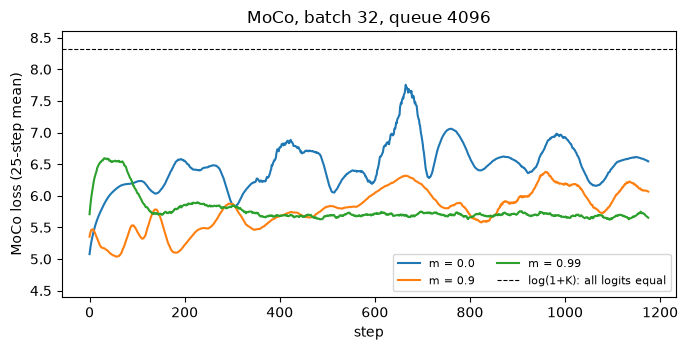

In [17]:
def train_moco(m, steps=1200, BS=32, K=4096, tau=0.2, seed=0):     # Colab GPU: steps=20000, m=0.999
    torch.manual_seed(seed)
    f_q = nn.Sequential(SmallCNN(), nn.Linear(64, 128), nn.ReLU(), nn.Linear(128, 64)).to(device)
    f_k = copy.deepcopy(f_q)                                # the key encoder: starts as a copy, never gets a gradient
    for p in f_k.parameters(): p.requires_grad_(False)
    opt = torch.optim.Adam(f_q.parameters(), lr=2e-3, weight_decay=1e-5)
    queue, losses = KeyQueue(K, 64, device), []
    for step in range(steps):
        xb = X_pre_d[torch.randint(0, N_PRE, (BS,), device=device)]
        q = F.normalize(f_q(augment(xb)), dim=1)
        with torch.no_grad():
            ema_update(f_k, f_q, m)
            k = F.normalize(f_k(augment(xb)), dim=1)
        loss = moco_loss(q, k, queue.keys, tau)
        opt.zero_grad(); loss.backward(); opt.step()
        queue.push(k)
        losses.append(loss.item())
    return f_q[0], losses                                   # the backbone, for the probe

MS, moco_enc, t0 = [0.0, 0.9, 0.99], {}, time.time()
fig, ax = plt.subplots(figsize=(7, 3.6))
for m in MS:
    moco_enc[m], losses = train_moco(m)
    acc[f"MoCo m={m}"] = probe(moco_enc[m])
    ax.plot(np.convolve(losses, np.ones(25) / 25, mode="valid"), label=f"m = {m}")
    print(f"m = {m:<4}: loss {np.mean(losses[:50]):.2f} -> {np.mean(losses[-50:]):.2f}, "
          f"linear probe {acc[f'MoCo m={m}']:.3f}   ({time.time() - t0:.0f}s)")
ax.axhline(math.log(4097), ls="--", c="k", lw=0.8, label="log(1+K): all logits equal")
ax.set(xlabel="step", ylabel="MoCo loss (25-step mean)", title="MoCo, batch 32, queue 4096", ylim=(4.4, 8.6)); ax.legend(loc="lower right", ncol=2, fontsize=8)
plt.tight_layout(); plt.show()

- $m = 0.99$: the loss settles at 5.7 and the probe reaches 0.379, above the random-init network (0.296).
- $m = 0$ and $m = 0.9$: the loss rises and oscillates (5.4 → 6.6 and 5.3 → 6.1) and the probe ends **below** the random-init network (0.234 and 0.255; a CPU run gives 0.187 and 0.290, against 0.294 at random init): nothing was learned, and with $m = 0$ the features became worse than random. With $m = 0.9$ the key encoder averages the last ≈ 9 query encoders, while the queue spans 128 steps, so most keys in it come from networks that no longer exist, and $q\cdot k$ for those keys compares features of different networks. The MoCo paper (Table 4) reports the same: $m = 0$ fails to converge, $m$ between 0.99 and 0.9999 works.
- This is not MoCo vs SimCLR: the runs differ in batch, steps and images seen (38k for MoCo, 58k for SimCLR), and neither is converged. The run isolates one thing, the momentum.

✏️ Train with `m = 0.999` (MoCo's value). Compare the loss curve and the probe with $m = 0.99$, and explain both with the last column of the table in 3.1.

**Past exam question (Moed B, 2026).** MoCo was designed to address the need for a large batch size in contrastive learning. Which of the following statements correctly describe how MoCo obtains a large number of negative samples without increasing the batch size? (More than one answer may be correct.)
1. MoCo replaces the InfoNCE loss with a loss that does not require negative samples.
2. MoCo effectively increases the batch size by accumulating gradients over several training steps.
3. MoCo uses a momentum encoder updated by an exponential moving average.
4. MoCo uses hard negative mining to reduce the number of samples needed.

**Answer: 3.** MoCo keeps a **queue** of keys from the last several batches (65,536 in the paper) and uses them as negatives; the keys are produced by a **momentum encoder**, $\theta_k\leftarrow m\theta_k+(1-m)\theta_q$ with $m=0.999$, so keys computed many steps apart come from nearly the same encoder and stay comparable (section 3.4: without it, training collapsed). The queue supplies the number of negatives, the EMA makes the queue usable. (1) is false: MoCo uses InfoNCE. (2) is false: gradient accumulation does not add negatives, since each step's softmax still sees only its own batch. (4) is false: the queue negatives are random, not mined.

## 4. CLIP and SigLIP

### 4.1 The CLIP loss: InfoNCE across modalities
The same InfoNCE, with an image and its caption as the positive pair. In a batch of $N$ pairs, row $i$ of the $N\times N$ image–text similarity matrix is an $N$-way classification over the captions (no image–image negatives, unlike SimCLR), column $j$ an $N$-way classification over the images, and the loss averages the two directions. CLIP learns the temperature: it stores $\log(1/\tau)$ as `logit_scale`, initialized at $\log(1/0.07)$, with $1/\tau$ clipped at 100.

We load `openai/clip-vit-base-patch32` (ViT-B/32 image tower, 12-layer text tower, both projected to 512-d) and compute the embeddings ourselves, `projection(tower(x).pooler_output)`, so the code does not depend on the `transformers` version.

In [18]:
clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").eval()
proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
for p in clip.parameters(): p.requires_grad_(False)

@torch.no_grad()
def embed_images(pil_images, bs=100):
    out = []
    for i in range(0, len(pil_images), bs):
        px = proc(images=pil_images[i:i + bs], return_tensors="pt").pixel_values
        out.append(clip.visual_projection(clip.vision_model(pixel_values=px).pooler_output))
    return torch.cat(out)

@torch.no_grad()
def embed_texts(texts):
    tok = proc(text=texts, return_tensors="pt", padding=True)
    return clip.text_projection(clip.text_model(**tok).pooler_output)

print("learned temperature: 1/tau = logit_scale.exp() =", round(clip.logit_scale.exp().item(), 2))

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

learned temperature: 1/tau = logit_scale.exp() = 100.0


In [19]:
def clip_loss(img, txt, logit_scale):
    img, txt = F.normalize(img, dim=-1), F.normalize(txt, dim=-1)
    logits = logit_scale.exp() * img @ txt.T
    targets = torch.arange(len(img))
    return (F.cross_entropy(logits, targets) + F.cross_entropy(logits.T, targets)) / 2

**Check: against `CLIPModel(..., return_loss=True)`** on 10 CIFAR-10 test images (one per class) paired with "a photo of a {class}.".

In [20]:
labels_all = np.array(cifar_te.targets)
idx = np.concatenate([np.where(labels_all == c)[0][:50] for c in range(10)])   # 50 test images per class
cifar_imgs = [cifar_te[i][0] for i in idx]
cifar_y = torch.tensor(labels_all[idx])
batch_imgs = [cifar_imgs[c * 50] for c in range(10)]
batch_txts = [f"a photo of a {c}." for c in CLASSES]
with torch.no_grad():
    ref = clip(**proc(text=batch_txts, images=batch_imgs, return_tensors="pt", padding=True), return_loss=True).loss
img10, txt10 = embed_images(batch_imgs), embed_texts(batch_txts)
mine = clip_loss(img10, txt10, clip.logit_scale)
print(f"mine {mine.item():.5f}   CLIPModel {ref.item():.5f}   |diff| = {abs(mine - ref).item():.2e}   chance log 10 = {math.log(10):.3f}")

mine 0.26984   CLIPModel 0.26984   |diff| = 5.07e-07   chance log 10 = 2.303


### 4.2 Zero-shot classification
One text embedding per class is the classifier's weight vector. With several prompt templates, normalize each template's embedding, average over the templates, and normalize again (prompt ensembling, as in the CLIP paper). No training image of these classes is used.

In [21]:
def zero_shot_weights(classnames, templates):
    W = []
    for c in classnames:
        t = F.normalize(embed_texts([tm.format(c) for tm in templates]), dim=-1)
        W.append(F.normalize(t.mean(0), dim=-1))
    return torch.stack(W)

t0 = time.time()
cifar_emb = F.normalize(embed_images(cifar_imgs), dim=-1)            # (500, 512)
print(f"embedded {len(cifar_imgs)} images in {time.time() - t0:.0f} s")
W1 = zero_shot_weights(CLASSES, ["a photo of a {}."])
with torch.no_grad():
    ref = clip(**proc(text=[f"a photo of a {c}." for c in CLASSES], images=cifar_imgs[:20], return_tensors="pt", padding=True)).logits_per_image
print("check, one template: max |mine − CLIPModel.logits_per_image| =", (clip.logit_scale.exp() * cifar_emb[:20] @ W1.T - ref).abs().max().item())

embedded 500 images in 4 s


check, one template: max |mine − CLIPModel.logits_per_image| = 3.4332275390625e-05


In [22]:
prompt_sets = {
    "class name only": ["{}"],
    '"a photo of a {}."': ["a photo of a {}."],
    "8-template ensemble": ["a photo of a {}.", "a blurry photo of a {}.", "a low resolution photo of a {}.",
                            "a photo of the small {}.", "a pixelated photo of a {}.", "a close-up photo of a {}.",
                            "a bright photo of a {}.", "a photo of the big {}."],
}
for name, templates in prompt_sets.items():
    pred = (cifar_emb @ zero_shot_weights(CLASSES, templates).T).argmax(1)
    print(f"{name:22s} zero-shot accuracy on 500 CIFAR-10 test images: {(pred == cifar_y).float().mean():.3f}")

class name only        zero-shot accuracy on 500 CIFAR-10 test images: 0.880
"a photo of a {}."     zero-shot accuracy on 500 CIFAR-10 test images: 0.898


8-template ensemble    zero-shot accuracy on 500 CIFAR-10 test images: 0.916


No CIFAR-10 training image was used: the class name alone gives 0.880, "a photo of a {}." 0.898, and the 8-template ensemble **0.916** on 500 test images (compare: 0.44 for the SimCLR probe above, trained on 2000 labeled images, with 5000 pretraining images instead of CLIP's 400M pairs). The template moves the embedding of a bare word toward that of a caption, the kind of text CLIP was trained on. The trained CLIP sits at the clip value, $1/\tau = 100$.

### 4.3 SigLIP: one sigmoid per pair
SigLIP turns the $N\times N$ matrix into $N^2$ independent binary questions, "is this a matching pair?": logits $t\,s_{ij} + b$ with a learned scale $t$ and bias $b$ (initialized at $t = 10$, $b = -10$, so that the $N^2 - N$ negatives start with a low loss), labels $z_{ii} = +1$, $z_{i\ne j} = -1$, and
$$\mathcal L = -\frac1N\sum_{i=1}^N\sum_{j=1}^N \log\sigma\big(z_{ij}\,(t\,s_{ij} + b)\big).$$

In [23]:
def siglip_loss(img, txt, t, b):
    # img, txt: (N, d), row i of each is a matching pair; t, b: scale and bias
    img, txt = F.normalize(img, dim=-1), F.normalize(txt, dim=-1)
    logits = t * img @ txt.T + b
    z = 2 * torch.eye(len(img), device=img.device) - 1
    return -F.logsigmoid(z * logits).sum() / len(img)

def siglip_reference(img, txt, t, b):
    # the formula, one pair at a time
    img, txt = F.normalize(img, dim=-1), F.normalize(txt, dim=-1); N, total = len(img), 0.0
    for i in range(N):
        for j in range(N):
            zij = 1.0 if i == j else -1.0
            total += -math.log(1 / (1 + math.exp(-zij * (t * (img[i] @ txt[j]).item() + b))))
    return total / N

print(f"CLIP embeddings of the 10 pairs: mine {siglip_loss(img10, txt10, 10.0, -10.0):.6f}   reference {siglip_reference(img10, txt10, 10.0, -10.0):.6f}")
cos10 = F.normalize(img10, dim=-1) @ F.normalize(txt10, dim=-1).T
print(f"cosine: matching pairs {cos10.diag().mean():.3f}, other pairs {cos10[~torch.eye(10, dtype=torch.bool)].mean():.3f}; "
      f"loss from the 10 matching pairs alone {-F.logsigmoid(10.0 * cos10.diag() - 10.0).sum() / 10:.4f}")

CLIP embeddings of the 10 pairs: mine 7.438175   reference 7.438175
cosine: matching pairs 0.257, other pairs 0.194; loss from the 10 matching pairs alone 7.4353


**Why it scales.** The sigmoid loss is a sum of $N^2$ independent terms, so any split of the pairs across devices adds up to the full loss: each device processes its block of the similarity matrix and never needs a whole row. The softmax loss of row $i$ depends on every text in the batch through its normalizer. Below, $N = 512$ random pairs split into 4 blocks of 128 texts, as 4 devices would see them.

In [24]:
torch.manual_seed(0)
u, v = torch.randn(512, 64), torch.randn(512, 64)
u = u + 0.5 * v                                              # matching pairs are correlated
chunks = torch.arange(512).chunk(4)
un, vn = F.normalize(u, dim=-1), F.normalize(v, dim=-1)
full_sig = siglip_loss(u, v, 10.0, -10.0)
blocks_sig = 0.0
for c in chunks:                                             # device c holds texts c and sees all 512 images
    z = -torch.ones(512, len(c)); z[c, torch.arange(len(c))] = 1
    blocks_sig += -F.logsigmoid(z * (10.0 * un @ vn[c].T - 10.0)).sum() / 512
print(f"sigmoid: full {full_sig:.5f}   sum of 4 blocks {blocks_sig:.5f}")
logits = un @ vn.T / 0.07
full_soft = F.cross_entropy(logits, torch.arange(512))
local_soft = torch.stack([F.cross_entropy(logits[c][:, c], torch.arange(len(c))) for c in chunks]).mean()
print(f"softmax (image -> text): full {full_soft:.5f}   rows normalized over their own block of 128 texts only {local_soft:.5f}")

sigmoid: full 5.65358   sum of 4 blocks 5.65358
softmax (image -> text): full 1.83415   rows normalized over their own block of 128 texts only 0.94588


The sigmoid loss of the 4 blocks adds up to the full loss exactly (5.65358). The softmax loss is 1.83 over all 512 texts but 0.95 when each row is normalized over its own block of 128: 4× fewer candidates make an easier task and a different number (section 2.4). So SigLIP can compute the matrix one block at a time, or one block per device, and add up; for the softmax every block needs the normalizer of the full row. On the 10 CIFAR pairs, CLIP's embeddings give a sigmoid loss of 7.44, and 7.435 of it comes from the 10 matching pairs: their cosine is 0.26 (other pairs 0.19), so with SigLIP's initial $t = 10$, $b = -10$ their logits, $10\cdot0.26-10\approx-7.4$, say "no match". The initialization assumes that no pair matches, which is right for the $N^2-N$ negatives; training moves $t$ and $b$ (and CLIP's embeddings were never trained for this loss).

## 5. DINO: centering and sharpening

DINO's loss is the cross-entropy between the teacher's distribution and the student's, on two different views, with an EMA teacher (the `ema_update` of section 3.1, $m = 0.996$). Nothing in the loss stops both networks from giving every image the same output. Two ways to collapse, two diagnostics on the teacher's output $p_t$ over a batch:
- **one dimension wins for every image**: the batch-mean distribution $\bar p_t$ concentrates on it, so the entropy of $\bar p_t$ drops toward 0;
- **uniform output for every image**: the per-image entropy of $p_t$ stays at its maximum, $\log K$.

A healthy teacher is sharp per image (entropy below $\log K$) and diverse over the batch (entropy of $\bar p_t$ near $\log K$). **Centering** subtracts $c$, a running mean of the teacher's outputs, so no dimension can be large for every image; **sharpening** divides by a small $\tau_t$, so the output cannot be flat.

### 5.1 The teacher's target

In [25]:
def dino_teacher_probs(zt, center, tau_t):
    # zt: (B, K) teacher outputs; center: (K,) running mean of zt; tau_t: teacher temperature
    return F.softmax((zt - center) / tau_t, dim=-1)

def update_center(center, zt, momentum=0.9):
    return momentum * center + (1 - momentum) * zt.mean(0)

def dino_loss(pt, zs, tau_s):
    # cross-entropy between the teacher's distribution and the student's
    return -(pt * F.log_softmax(zs / tau_s, dim=-1)).sum(-1).mean()

In [26]:
torch.manual_seed(0)
zt, zs = torch.randn(6, 8), torch.randn(6, 8)
print("center after one update from 0 equals 0.1 · batch mean:", torch.allclose(update_center(torch.zeros(8), zt), 0.1 * zt.mean(0)))
pt = dino_teacher_probs(zt, zt.mean(0), 0.04)
print(f"dino_loss {dino_loss(pt, zs, 0.1):.6f}   F.cross_entropy with probability targets {F.cross_entropy(zs / 0.1, pt):.6f}")
shift = torch.zeros(8); shift[3] = 5.0                       # the same offset in output 3 for every image
print("argmax per image, raw:        ", (zt + shift).argmax(1).tolist())
print("argmax per image, centered:   ", dino_teacher_probs(zt + shift, (zt + shift).mean(0), 0.04).argmax(1).tolist())
print("centering removes the shared offset exactly: max |Δp| =", (dino_teacher_probs(zt + shift, (zt + shift).mean(0), 0.04) - pt).abs().max().item())
for tau_t in (1.0, 0.04):
    p = dino_teacher_probs(zt, zt.mean(0), tau_t)
    print(f"tau_t = {tau_t:<4}: mean per-image entropy {-(p * p.clamp_min(1e-12).log()).sum(-1).mean():.3f} nats (uniform: log 8 = {math.log(8):.3f})")

center after one update from 0 equals 0.1 · batch mean: True
dino_loss 19.515114   F.cross_entropy with probability targets 19.515114
argmax per image, raw:         [3, 3, 3, 3, 3, 3]
argmax per image, centered:    [4, 6, 7, 0, 7, 5]
centering removes the shared offset exactly: max |Δp| = 1.1324274851176597e-14
tau_t = 1.0 : mean per-image entropy 1.797 nats (uniform: log 8 = 2.079)
tau_t = 0.04: mean per-image entropy 0.043 nats (uniform: log 8 = 2.079)


### 5.2 Three runs
150 steps of DINO on the CIFAR subset with $K = 64$ outputs, $\tau_s = 0.1$, in three settings: sharpening only ($\tau_t = 0.04$, no centering), centering only ($\tau_t = 1$), and both.

sharpening only          final: per-image entropy 1.55, batch-mean entropy 1.91  (log K = 4.16)


centering only           final: per-image entropy 4.16, batch-mean entropy 4.16  (log K = 4.16)


centering + sharpening   final: per-image entropy 3.66, batch-mean entropy 4.12  (log K = 4.16)


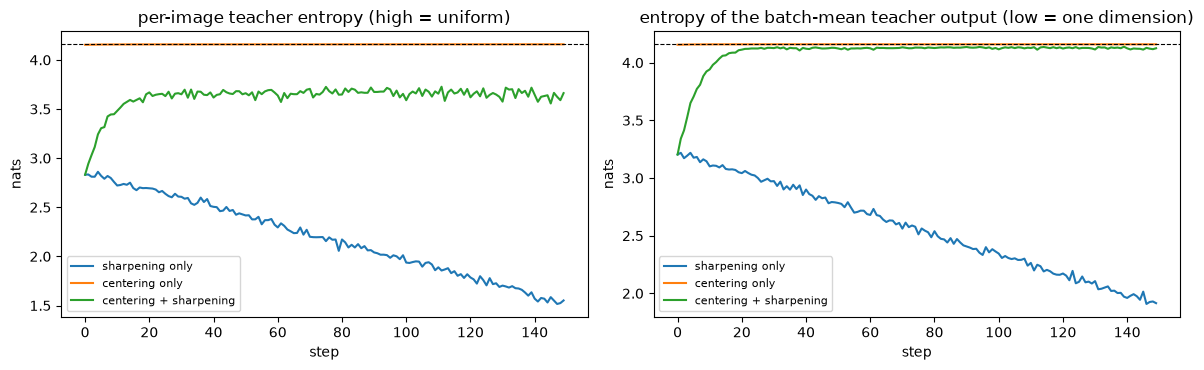

In [27]:
def run_dino(center, tau_t, steps=150, K=64, tau_s=0.1, m=0.996, seed=0):
    torch.manual_seed(seed)
    student = nn.Sequential(SmallCNN(), nn.Linear(64, 256), nn.GELU(), nn.Linear(256, K)).to(device)
    teacher = nn.Sequential(SmallCNN(), nn.Linear(64, 256), nn.GELU(), nn.Linear(256, K)).to(device)
    teacher.load_state_dict(student.state_dict())
    for p in teacher.parameters(): p.requires_grad_(False)
    opt = torch.optim.AdamW(student.parameters(), lr=1e-3, weight_decay=0.04)
    c = torch.zeros(K, device=device)
    H_img, H_mean = [], []
    for step in range(steps):
        xb = X_pre_d[torch.randint(0, N_PRE, (64,), device=device)]
        v1, v2 = augment(xb), augment(xb)
        with torch.no_grad():
            zt = teacher(torch.cat([v1, v2]))
            pt = dino_teacher_probs(zt, c if center else torch.zeros_like(c), tau_t)
            if center: c = update_center(c, zt)
        loss = dino_loss(pt, student(torch.cat([v2, v1])), tau_s)       # each view predicts the other view's teacher
        opt.zero_grad(); loss.backward(); opt.step()
        ema_update(teacher, student, m)
        with torch.no_grad():
            H_img.append(-(pt * pt.clamp_min(1e-12).log()).sum(-1).mean().item())
            pm = pt.mean(0); H_mean.append(-(pm * pm.clamp_min(1e-12).log()).sum().item())
    return student[0], H_img, H_mean

configs = {"sharpening only": (False, 0.04), "centering only": (True, 1.0), "centering + sharpening": (True, 0.04)}
dino_enc = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for name, (cen, tt) in configs.items():
    dino_enc[name], H_img, H_mean = run_dino(cen, tt)
    axes[0].plot(H_img, label=name); axes[1].plot(H_mean, label=name)
    print(f"{name:24s} final: per-image entropy {H_img[-1]:.2f}, batch-mean entropy {H_mean[-1]:.2f}  (log K = {math.log(64):.2f})")
for a, t in zip(axes, ["per-image teacher entropy (high = uniform)", "entropy of the batch-mean teacher output (low = one dimension)"]):
    a.axhline(math.log(64), ls="--", c="k", lw=0.8); a.set(title=t, xlabel="step", ylabel="nats"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

- **Sharpening only:** both entropies fall steadily, to 1.55 (per image) and 1.91 (batch mean) nats after 150 steps, and are still falling. The batch-mean distribution concentrates on a few outputs shared by all images: collapse toward one dimension.
- **Centering only:** both entropies sit at $\log K = 4.16$ from the start (the orange curve is under the dashed line): every image gets the uniform distribution, and the loss carries no information. (In 5.1, $\tau_t = 1$ already gave 1.80 of the maximal 2.08 nats.)
- **Both:** batch-mean entropy 4.12 ≈ $\log K$ (all outputs used), per-image entropy 3.66, below $\log K$. At this scale the teacher is only mildly sharp; DINO trains for hundreds of epochs and warms $\tau_t$ up from 0.04 to 0.07.

**Past exam question (Moed C, 2026).** DINO is a visual self-supervised method that uses two networks with the same architecture: a student $f_s$ and a teacher $f_t$. They receive two different views (augmentations) of the same image, and the goal is for $f_s$ to learn to match its output to $f_t$'s. In DINO $f_t$ is not trained directly by backpropagation; instead it is an Exponential Moving Average (EMA) of the student's weights:
$$\theta_t\leftarrow m\,\theta_t+(1-m)\,\theta_s,\qquad m\in[0,1).$$
**Explain why, without this mechanism (or a similar one), training a self-supervised network with two identical networks may collapse (representation collapse), i.e. the networks learn a constant output that does not depend on the input.** Refer to the loss function and to how the EMA prevents the collapse.

**Answer (official solution).** The loss is the cross-entropy $\mathcal L=-\sum_k p_t^{(k)}\log p_s^{(k)}$ between the teacher's and the student's distributions on two views. It only asks the two outputs to agree, and a constant output $f_s(x)=f_t(x)=c$ for every $x$ agrees perfectly: minimal loss, useless features. If both networks were trained by gradient descent on this symmetric loss, each could move toward the other and they would reach the constant solution quickly. With the EMA the teacher receives no gradient and changes slowly: it is a stable, slowly moving target (a temporal ensemble of past students), the student cannot pull the teacher along with it, and the asymmetry slows the drift to the trivial solution. BYOL uses the same mechanism.

**Where we disagree with the official solution.** The EMA is not what prevents collapse in DINO; centering and sharpening do. All three runs in section 5.2 use the EMA teacher ($m=0.996$), and two of them collapse: sharpening only (one dimension wins, batch-mean entropy falling) and centering only (uniform output, both entropies at $\log K$). Only centering + sharpening stays healthy. The DINO paper reports the same (Caron et al. 2021, Sec. 5.3 / Fig. 7): with a momentum teacher but without centering or without sharpening, training collapses. The official solution mentions centering and sharpening as a "complementary note"; they are the anti-collapse mechanism, and the EMA's role is to make the teacher a better, stabler target (with a teacher that simply copies the student, $m=0$, the paper reports that training does not converge). In MoCo (section 3.4) the EMA has a different job: keeping the keys in the queue comparable.

## 6. Effective rank: detecting collapse without labels
A collapsed encoder maps every image to a few directions, so its feature matrix has a few large singular values and the rest near 0. **RankMe** (Garrido et al., ICML 2023) turns the spectrum into one number: with singular values $\sigma_1,\dots,\sigma_d$ of the $n\times d$ feature matrix $H$ and $p_k = \sigma_k/\sum_j\sigma_j$,
$$\mathrm{RankMe}(H) = \exp\Big(-\sum_k p_k\log p_k\Big) \in [1, d],$$
the exponential of the entropy of the spectrum: $r$ equal singular values give exactly $r$. It needs no labels, so it can be logged during pretraining.

In [28]:
def rankme(H, eps=1e-7):
    # H: (n, d) features of n images -> effective rank, a float in [1, d]
    s = torch.linalg.svdvals(H.double())
    p = s / s.sum() + eps
    return math.exp(-(p * p.log()).sum().item())

torch.manual_seed(0)
for r in (1, 5, 30):
    U, _ = torch.linalg.qr(torch.randn(1000, r)); V, _ = torch.linalg.qr(torch.randn(64, r))
    Hr = U @ V.T                                              # 1000 x 64 with exactly r singular values, all equal to 1
    print(f"r = {r:2d} equal singular values: rankme {rankme(Hr):.3f}   torch.linalg.matrix_rank {torch.linalg.matrix_rank(Hr).item()}")

r =  1 equal singular values: rankme 1.000   torch.linalg.matrix_rank 1
r =  5 equal singular values: rankme 5.000   torch.linalg.matrix_rank 5
r = 30 equal singular values: rankme 30.002   torch.linalg.matrix_rank 30


Every encoder trained in this notebook, on the same 1000 test images: RankMe of the 64-d backbone features against the linear-probe accuracy (which needs labels).

random init                    RankMe  16.8   linear probe 0.296
SimCLR                         RankMe  25.6   linear probe 0.439
MoCo m=0.0                     RankMe   2.8   linear probe 0.234
MoCo m=0.9                     RankMe   2.8   linear probe 0.255
MoCo m=0.99                    RankMe  23.1   linear probe 0.379


DINO, sharpening only          RankMe  25.3   linear probe 0.354


DINO, centering only           RankMe  11.0   linear probe 0.254


DINO, centering + sharpening   RankMe  26.1   linear probe 0.375


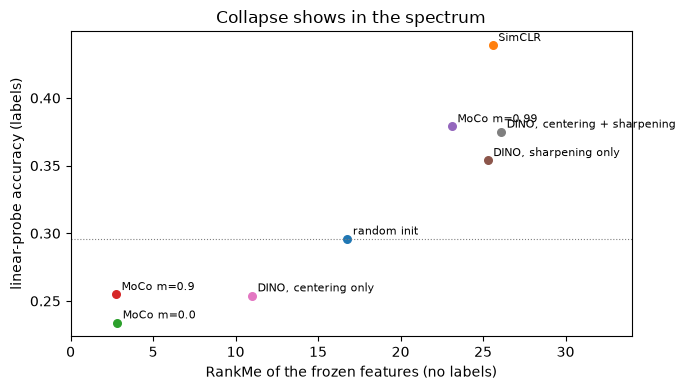

In [29]:
encoders = {"random init": rand_enc, "SimCLR": enc, **{f"MoCo m={m}": moco_enc[m] for m in MS},
            **{f"DINO, {k}": v for k, v in dino_enc.items()}}
rk = {}
for name, f in encoders.items():
    if name not in acc: acc[name] = probe(f)
    rk[name] = rankme(extract(f, X_te))
    print(f"{name:30s} RankMe {rk[name]:5.1f}   linear probe {acc[name]:.3f}")
fig, ax = plt.subplots(figsize=(7, 4))
for name in encoders:
    ax.scatter(rk[name], acc[name], s=30)
    ax.annotate(name, (rk[name], acc[name]), textcoords="offset points", xytext=(4, 3), fontsize=8)
ax.axhline(acc["random init"], ls=":", c="0.5", lw=0.8); ax.set_xlim(0, 34)
ax.set(xlabel="RankMe of the frozen features (no labels)", ylabel="linear-probe accuracy (labels)", title="Collapse shows in the spectrum")
plt.tight_layout(); plt.show()

The runs whose probe fell **below the random-init network** (dotted line) have the lowest RankMe: MoCo with $m \le 0.9$ (2.8: the 64-d features live in about 3 directions) and DINO with centering only (11.0), against 16.8 at random init and 23–26 for the runs that learned. Among the healthy runs RankMe does not order the probe accuracy (SimCLR 25.6 → 0.439, DINO centering + sharpening 26.1 → 0.375), and it measures the backbone: the sharpening-only DINO run is collapsing in its output head (section 5.2), but after 150 steps its backbone is still fine (25.3, probe 0.354). Use it as an alarm during pretraining: a falling RankMe means collapse, and it needs no labels. (A CPU run gives somewhat different values, 3.2 and 5.1 for MoCo with $m = 0$ and $0.9$, 13.8 for DINO with centering only; the gap to the runs that learned stays.)

✏️ Log `rankme(extract(f_q[0], X_te))` every 200 steps inside `train_moco` for $m = 0$ and $m = 0.99$. At which step does the $m = 0$ run collapse?

## 7. If time: what to hide, random patches or blocks
MAE hides 75% of the patches at random; V-JEPA hides big blocks: a union of 8 blocks of 15% of the frame each (short-range) or 2 blocks of 70% (long-range), with aspect ratios in $(0.75, 1.5)$, the same blocks in every frame. Why blocks? With random patches almost every hidden patch has a visible neighbour, and copying the neighbour is already a good guess; a hidden block can only be filled by knowing what is there.

**The sampler**, as in the official code (`src/masks/multiblock3d.py`): a block of `int(G·G·scale)` patches with a random aspect ratio, placed at random, `n_blocks` times; the mask is their union.

In [30]:
def block_mask(n_blocks, scale, G, rng, ar=(0.75, 1.5)):
    # (G, G) boolean mask, True = hidden: the union of n_blocks rectangles of about scale*G*G patches each
    keep = int(G * G * scale)
    a = ar[0] + rng.random() * (ar[1] - ar[0])
    h, w = min(G, int(round(math.sqrt(keep * a)))), min(G, int(round(math.sqrt(keep / a))))
    m = np.zeros((G, G), bool)
    for _ in range(n_blocks):
        t, l = rng.integers(0, G - h + 1), rng.integers(0, G - w + 1)
        m[t:t + h, l:l + w] = True
    return m

rng = np.random.default_rng(0)
for n, s, official in [(8, 0.15, 0.63), (2, 0.70, 0.82)]:
    frac = np.mean([block_mask(n, s, 14, rng).mean() for _ in range(2000)])
    print(f"{n} blocks of {s:.0%} on V-JEPA's 14 x 14 grid: {frac:.1%} hidden   (the official sampler: about {official:.0%})")

8 blocks of 15% on V-JEPA's 14 x 14 grid: 62.7% hidden   (the official sampler: about 63%)
2 blocks of 70% on V-JEPA's 14 x 14 grid: 81.4% hidden   (the official sampler: about 82%)


**Copying the nearest visible patch.** A $32\times32$ image as a $16\times16$ grid of $2\times2$ patches. For each image: a block mask, and a random mask that hides the same number of patches. Every hidden patch is filled with the nearest visible patch (grid distance); the error is the MSE on the hidden pixels. Reference: filling every hidden pixel with the image's mean color.

8 blocks of 15% (62% hidden): copy-fill MSE blocks 0.0502 vs random 0.0256; nearest visible patch 2.47 vs 1.11 patches away


2 blocks of 70% (81% hidden): copy-fill MSE blocks 0.0635 vs random 0.0321; nearest visible patch 4.82 vs 1.47 patches away
mean-color fill (any mask): MSE 0.0447


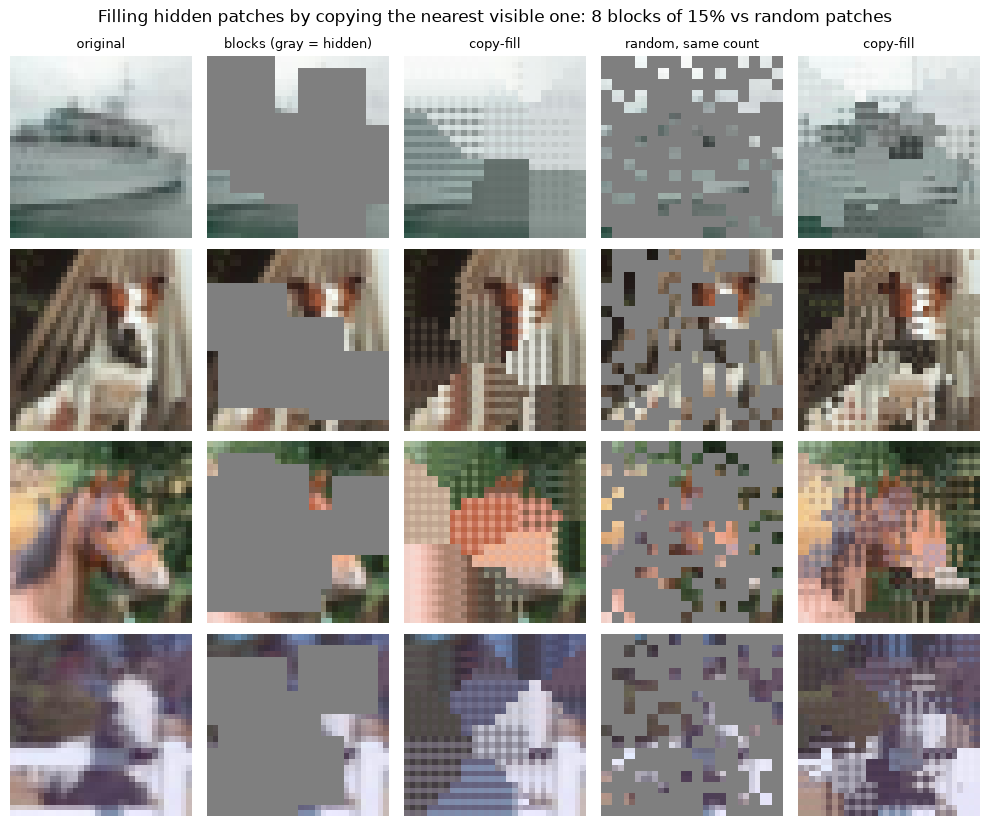

In [31]:
G, P = 16, 2
def random_mask(n_hidden, G, rng):
    m = np.zeros(G * G, bool); m[rng.permutation(G * G)[:n_hidden]] = True
    return m.reshape(G, G)

def copy_fill(img, m):
    # every hidden patch <- the nearest visible patch; returns the filled image and the mean distance (in patches)
    pt = img.reshape(3, G, P, G, P).permute(1, 3, 0, 2, 4).clone()          # (G, G, 3, P, P)
    vis, hid = np.argwhere(~m), np.argwhere(m)
    dist = np.sqrt(((hid[:, None, :] - vis[None, :, :]) ** 2).sum(-1))
    src = vis[dist.argmin(1)]
    pt[hid[:, 0], hid[:, 1]] = pt[src[:, 0], src[:, 1]]
    return pt.permute(2, 0, 3, 1, 4).reshape(3, G * P, G * P), dist.min(1).mean()

rng = np.random.default_rng(0)
X_m = X_te[:500]
examples = {}
for name, (n, s) in {"8 blocks of 15%": (8, 0.15), "2 blocks of 70%": (2, 0.70)}.items():
    err, dist, frac = {"blocks": [], "random": []}, {"blocks": [], "random": []}, []
    for i in range(len(X_m)):
        mb = block_mask(n, s, G, rng)
        while mb.all(): mb = block_mask(n, s, G, rng)                    # keep at least one visible patch
        masks = {"blocks": mb, "random": random_mask(int(mb.sum()), G, rng)}
        for kind, m_ in masks.items():
            filled, dd = copy_fill(X_m[i], m_)
            hid_px = torch.from_numpy(m_).repeat_interleave(P, 0).repeat_interleave(P, 1)
            err[kind].append(((filled - X_m[i]) ** 2)[:, hid_px].mean().item()); dist[kind].append(dd)
            if i < 4: examples[(name, kind, i)] = (m_, filled)
        frac.append(mb.mean())
    print(f"{name} ({np.mean(frac):.0%} hidden): copy-fill MSE blocks {np.mean(err['blocks']):.4f} vs random {np.mean(err['random']):.4f}; "
          f"nearest visible patch {np.mean(dist['blocks']):.2f} vs {np.mean(dist['random']):.2f} patches away")
print(f"mean-color fill (any mask): MSE {((X_m - X_m.mean((2, 3), keepdim=True)) ** 2).mean():.4f}")

fig, axes = plt.subplots(4, 5, figsize=(10, 8.4))
for i in range(4):
    cols = [X_m[i]]
    for kind in ("blocks", "random"):
        m_, filled = examples[("8 blocks of 15%", kind, i)]
        hid_px = torch.from_numpy(m_).repeat_interleave(P, 0).repeat_interleave(P, 1)
        cols += [torch.where(hid_px, torch.tensor(0.5), X_m[i]), filled]
    for j, im in enumerate(cols):
        axes[i, j].imshow(im.permute(1, 2, 0).numpy()); axes[i, j].axis("off")
for j, t in enumerate(["original", "blocks (gray = hidden)", "copy-fill", "random, same count", "copy-fill"]):
    axes[0, j].set_title(t, fontsize=9)
fig.suptitle("Filling hidden patches by copying the nearest visible one: 8 blocks of 15% vs random patches"); plt.tight_layout(); plt.show()

- Random patches: a hidden patch is on average 1.1 patches from a visible one (1.5 at 81% hidden), and copying it gives MSE 0.026 (0.032), below the mean-color fill (0.045).
- Blocks: the nearest visible patch is 2.5 patches away (4.8 for the long-range blocks), and copying is **worse** than the mean color: 0.050 (0.064).

Random patches can be filled from their neighbours with no idea of what is in the image; blocks cannot. This is why MAE needs a high masking ratio (75%), and why I-JEPA and V-JEPA hide whole blocks, V-JEPA the same blocks in every frame (the next frame shows almost the same pixels).

## Summary
- **InfoNCE** = cross-entropy on the rows of a similarity matrix; the positive is the other view (SimCLR) or the caption (CLIP, in both directions). Each negative is pushed with weight $p_i/\tau$, so hard negatives carry the gradient (1100× in 2.3).
- **$\log N - \mathcal L \le \log N$**: certifying more shared information takes more candidates (5.6 of 6 nats at $N = 4096$). Hence big batches (SimCLR, CLIP), a queue (MoCo), or a loss without the softmax normalizer (SigLIP).
- **EMA** = a geometric average of past weights with mean age $m/(1-m)$ steps. In MoCo it keeps the queued keys comparable: $m \le 0.9$ failed (probe at or below random init), $m = 0.99$ trained.
- **CLIP zero-shot**: the text embeddings are the classifier; the prompts matter (0.880 → 0.916 on CIFAR-10).
- **DINO**: centering stops one output from winning for every image, sharpening stops the uniform output; either alone collapses, although every run has the EMA teacher.
- **RankMe** flags collapse without labels (2.8–11 for the failed runs here, 3–14 on CPU, against 23–26 for the runs that learned).
- **What to hide**: random patches are filled by copying a neighbour, blocks are not, so block masks make the model predict content.

**Further watching:** NYU Deep Learning, LeCun & Canziani, energy-based and self-supervised learning lectures, https://atcold.github.io/NYU-DLSP21/ ; Lilian Weng, *Contrastive Representation Learning* (2021), https://lilianweng.github.io/posts/2021-05-31-contrastive/ ; UvA DL notebooks (Tutorial 17, SimCLR), https://uvadlc-notebooks.readthedocs.io/en/latest/ ; Meta, V-JEPA 2, https://ai.meta.com/vjepa/ .

In [32]:
print(f"total runtime: {(time.time() - T0) / 60:.1f} min")

total runtime: 0.8 min
